# **TP 1 Deep Learning - Régression pénalisée**

***Exo 1: Ridge et lasso avec scikit-learn***

In [ ]:
import pandas as pd
import numpy as np

# Chargement des donnees
ozone = pd.read_csv("drive/MyDrive/Machine Learning/Cours 1/ozone.csv", sep=";")
print(ozone.head())


   maxO3    T9   T12   T15  Ne9  Ne12  Ne15     Vx9    Vx12    Vx15  maxO3v  \
0     87  15.6  18.5  18.4    4     4     8  0.6946 -1.7101 -0.6946      84   
1     82  17.0  18.4  17.7    5     5     7 -4.3301 -4.0000 -3.0000      87   
2     92  15.3  17.6  19.5    2     5     4  2.9544  1.8794  0.5209      82   
3    114  16.2  19.7  22.5    1     1     0  0.9848  0.3473 -0.1736      92   
4     94  17.4  20.5  20.4    8     8     7 -0.5000 -2.9544 -4.3301     114   

    vent pluie  
0   Nord   Sec  
1   Nord   Sec  
2    Est   Sec  
3   Nord   Sec  
4  Ouest   Sec  


In [ ]:
# On separe la variable cible des variables explicatives
y = ozone['maxO3']
# On binarise les variables qualitatives et on enleve la premiere modalite
X = pd.get_dummies(ozone.drop('maxO3', axis =1), drop_first=True)

**Question 1 & 3:**

[ 0.0190815   1.94662978  0.50432168 -2.11766612 -0.61391991  0.03087743
  0.5182235   0.37313506  0.68863767  0.34817341 -0.72784177  3.60126607
  3.75731096  3.01117767]
[ 0.          2.26994968  0.50373638 -2.19467894 -0.12894782 -0.
  0.87332699  0.05151918  0.35631334  0.3573491  -0.          0.
  0.          0.        ]
[ 0.02668125  1.92211681  0.57179077 -2.10744511 -0.62226955  0.09130778
  0.6088089   0.22848699  0.62416341  0.35109725 -1.51359075  1.7488436
  2.06295466  2.40106771]
[ 0.          1.94927864  0.75264476 -1.90492215 -0.         -0.
  0.52822606  0.05647921  0.20510096  0.38028864 -0.         -0.
  0.          0.        ]
[ 0.22689754  1.70990908  0.77415678 -1.88636165 -0.71806406  0.15892398
  0.81449628  0.14132612  0.49364947  0.35054755 -0.70829546  0.39237214
  0.50852861  0.81120327]
[ 0.          0.          0.24568483 -0.         -0.         -0.
  0.          0.          0.          0.59689428 -0.         -0.
  0.          0.        ]


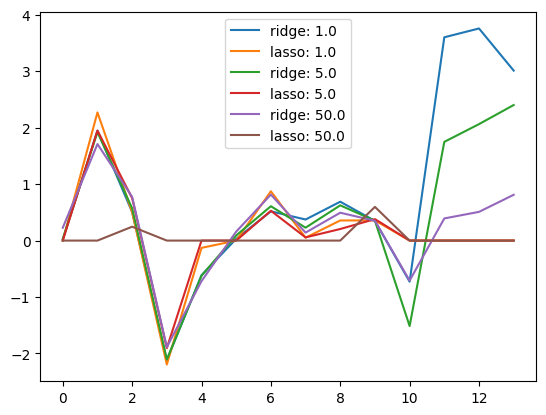

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, Lasso


# On definit les valeurs de alpha
alphas = [1.0, 5.0, 50.0]

for a in alphas :
  r = Ridge(alpha= a)
  r.fit(X, y)
  print(r.coef_)
  plt.plot(r.coef_  , label = f"ridge: {a}")

  l = Lasso(alpha= a)
  l.fit(X,y)
  print(l.coef_)
  plt.plot(l.coef_  , label = f"lasso: {a}")

plt.legend()
plt.show()

**Question 4:**

Pour savoir quelle valeur de $\alpha$ choisit le meilleur modèle, on ne peut pas tester sur les mêmes données que celles utilisées pour l'entraîner (sinon le modèle triche et on risque du sur-apprentissage).La validation croisée coupe tes données en plusieurs morceaux (par exemple 5) :

On entraîne le modèle sur 4 morceaux.

On teste sa prédiction sur le 5ᵉ morceau (qu'il n'a jamais vu).

On répète l'opération en changeant de morceau de test.

On calcule l'erreur moyenne (MSE) sur l'ensemble.

le meilleur alpha de ridge est: 10.0
le meilleur alpha de lasso est: 5.0
La RMSE de ridge est : 13.534531752574132
La MSE de ridge est : 183.18354976143743
La RMSE de lasso est : 13.854137104566417
La MSE de lasso est : 191.93711491212397


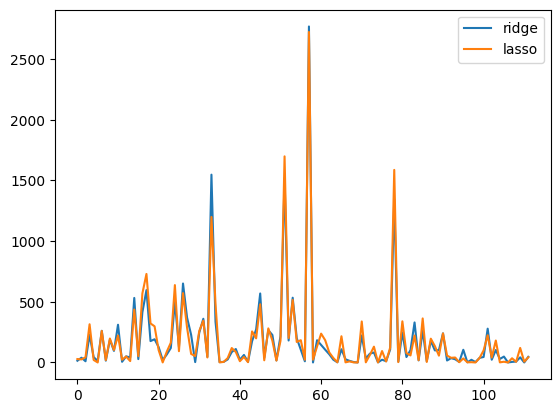

In [ ]:
from sklearn.linear_model import RidgeCV, LassoCV
import numpy as np

r_cv = RidgeCV(alphas=[1.0, 5.0, 10.0])
r_cv.fit(X, y)

l_cv = LassoCV(alphas=[1.0, 5.0, 10.0])
l_cv.fit(X, y)

print(f"le meilleur alpha de ridge est: {r_cv.alpha_}")
print(f"le meilleur alpha de lasso est: {l_cv.alpha_}")

mse_ridge = (y-r_cv.predict(X))**2
mse_lasso = (y-l_cv.predict(X))**2

print(f"La RMSE de ridge est : {np.sqrt(mse_ridge.mean())}")
print(f"La MSE de ridge est : {(mse_ridge.mean())}")
print(f"La RMSE de lasso est : {np.sqrt(mse_lasso.mean())}")
print(f"La MSE de lasso est : {(mse_lasso.mean())}")

plt.plot(mse_ridge, label = "ridge")
plt.plot(mse_lasso, label = "lasso")
plt.legend()
plt.show()


note : plot (y - r_cv.predict(X))² --> MSE mais avec root_mean_square_error ca rend nulle donc fait a la main



**Question 5 :**

J'utilise mes modèles r_cv et l_cv que j'ai entraîné à la question 4

In [ ]:
#je visualise vite fait les lignes 25 et 50 de mon jeu de données, c'est à partir de ca que je vais prédire:
X.iloc[[24, 49]]

,T9,T12,T15,Ne9,Ne12,Ne15,Vx9,Vx12,Vx15,maxO3v,vent_Nord,vent_Ouest,vent_Sud,pluie_Sec
24,20.1,22.4,22.8,7,6,7,-5.6382,-3.8302,-4.5963,83,False,True,False,False
49,18.8,22.5,23.9,6,3,2,0.5209,-1.0000,-2.0000,72,True,False,False,True


In [ ]:
nouvelles_lignes = X.iloc[[24, 49]]

prediction_ridge = r_cv.predict(nouvelles_lignes)
prediction_lasso = l_cv.predict(nouvelles_lignes)

print(f"La vraie valeur de la 25eme ligne est : {y.iloc[24]} et la prédiction de Ridge pour cette ligne est : {prediction_ridge[0]}")
print(f"La vraie valeur de la 50eme ligne est : {y.iloc[49]} et la prédiction de Ridge pour cette ligne est : {prediction_ridge[1]}")

print(f"La vraie valeur de la 25eme ligne est : {y.iloc[24]} et la prédiction de Lasso pour cette ligne est : {prediction_lasso[0]}")
print(f"La vraie valeur de la 50eme ligne est : {y.iloc[49]} et la prédiction de Lasso pour cette ligne est : {prediction_lasso[1]}")

La vraie valeur de la 25eme ligne est : 57 et la prédiction de Ridge pour cette ligne est : 79.3301616483162
La vraie valeur de la 50eme ligne est : 81 et la prédiction de Ridge pour cette ligne est : 85.14009307010868
La vraie valeur de la 25eme ligne est : 57 et la prédiction de Lasso pour cette ligne est : 82.25208920745249
La vraie valeur de la 50eme ligne est : 81 et la prédiction de Lasso pour cette ligne est : 84.9424215959906


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Question 6:**

In [ ]:
# Chargement du jeu de donnees complet et suppression des valeurs manquantes
ozone1 = pd.read_csv("/content/drive/MyDrive/Machine Learning/Cours 1/ozone_complet.csv", sep=";").dropna ()

# Preparation des donnees
y1 = ozone1['maxO3']
X1 = pd.get_dummies(ozone1.drop('maxO3', axis =1), drop_first=True)
print(ozone.head())

   maxO3    T9   T12   T15  Ne9  Ne12  Ne15     Vx9    Vx12    Vx15  maxO3v  \
0     87  15.6  18.5  18.4    4     4     8  0.6946 -1.7101 -0.6946      84   
1     82  17.0  18.4  17.7    5     5     7 -4.3301 -4.0000 -3.0000      87   
2     92  15.3  17.6  19.5    2     5     4  2.9544  1.8794  0.5209      82   
3    114  16.2  19.7  22.5    1     1     0  0.9848  0.3473 -0.1736      92   
4     94  17.4  20.5  20.4    8     8     7 -0.5000 -2.9544 -4.3301     114   

    vent pluie  
0   Nord   Sec  
1   Nord   Sec  
2    Est   Sec  
3   Nord   Sec  
4  Ouest   Sec  


Dans la question 6, l'objectif est d'évaluer et de comparer la capacité de généralisation de trois modèles différents :

MCO (LinearRegression) : régression linéaire classique sans pénalité.

Ridge (Ridge ou RidgeCV) : régression pénalisée $L_2$.

Lasso (Lasso ou LassoCV) : régression pénalisée $L_1$.


On utilise la fonction cross_val_score de sklearn.model_selection. Elle découpe automatiquement les données en $K$ blocs (par exemple $K=5$), entraîne le modèle sur 4 blocs, évalue le score sur le bloc restant, puis calcule la moyenne des scores des 5 étapes.   

VIRE LA PREMIERE COLONNE DU FICHIER OZONE_COMPLET

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import RidgeCV, LassoCV, LinearRegression

#Mes 3 modèles à comparer:
mco = LinearRegression()
ridge = RidgeCV(alphas=[1.0, 5.0, 10.0])
lasso = LassoCV(alphas=[1.0, 5.0, 10.0])

#comparer avec negative cross val score:
scores_mco = cross_val_score(mco, X1, y1, cv=5)
scores_ridge = cross_val_score(ridge, X1, y1, cv=5)
scores_lasso = cross_val_score(lasso, X1, y1, cv =5)

#Comparaison (MSE moyenne)
print(f"MSE MCO: {scores_mco.mean()}")
print(f"MSE Ridge: {scores_ridge.mean()}")
print(f"MSE Lasso: {scores_lasso.mean()}")



MSE MCO: 0.6398894712952929
MSE Ridge: 0.639953788258012
MSE Lasso: 0.6343707936506726


Note de correction de TP:

estimateur translaté puis tronquer donc il y a une séléction, certaines valeurs va etre mise à 0, c'est pour ca que dans le graph lasso il y a des cassures comme ca


exo 2:
phénomène de surapprentissage question 2
derniere question : 1er coeff c'est la constante